In [1]:
def get_wt(fname):
    # df=h5py.File("/home/jihenghu/JHCanoe/build_euler_apative_bg/bin/juno_mwr_rt_fwd-main.nc","r")
    import h5py
    import numpy as np

    df=h5py.File(fname,"r")
    tau1=np.array(df["CH1-tau"][0,:,0,0])
    tau2=np.array(df["CH2-tau"][0,:,0,0])
    tau3=np.array(df["CH3-tau"][0,:,0,0])
    tau4=np.array(df["CH4-tau"][0,:,0,0])
    tau5=np.array(df["CH5-tau"][0,:,0,0])
    tau6=np.array(df["CH6-tau"][0,:,0,0])
    temp=np.array(df["temp"][0,:,0,0])
    z=np.array(df["x1"])

    w1=[0]*1600
    w2=[0]*1600
    w3=[0]*1600
    w4=[0]*1600
    w5=[0]*1600
    w6=[0]*1600

    for i in np.arange(len(temp)-1-1,-1,-1):
        # print(i)
        tau1[i]= tau1[i]+tau1[i+1]
        tau2[i]= tau2[i]+tau2[i+1]
        tau3[i]= tau3[i]+tau3[i+1]
        tau4[i]= tau4[i]+tau4[i+1]
        tau5[i]= tau5[i]+tau5[i+1]
        tau6[i]= tau6[i]+tau6[i+1]


    # from top to bottom  
    for i in np.arange(len(temp)-1-1,-1,-1):
        TeTau1=( temp[i]*np.exp(-1*tau1[i]) +  temp[i-1]*np.exp(-1*tau1[i+1]) )*0.5
        TeTau2=( temp[i]*np.exp(-1*tau2[i]) +  temp[i-1]*np.exp(-1*tau2[i+1]) )*0.5
        TeTau3=( temp[i]*np.exp(-1*tau3[i]) +  temp[i-1]*np.exp(-1*tau3[i+1]) )*0.5
        TeTau4=( temp[i]*np.exp(-1*tau4[i]) +  temp[i-1]*np.exp(-1*tau4[i+1]) )*0.5
        TeTau5=( temp[i]*np.exp(-1*tau5[i]) +  temp[i-1]*np.exp(-1*tau5[i+1]) )*0.5
        TeTau6=( temp[i]*np.exp(-1*tau6[i]) +  temp[i-1]*np.exp(-1*tau6[i+1]) )*0.5

        dtau1= tau1[i]-tau1[i+1]
        dtau2= tau2[i]-tau2[i+1]
        dtau3= tau3[i]-tau3[i+1]
        dtau4= tau4[i]-tau4[i+1]
        dtau5= tau5[i]-tau5[i+1]
        dtau6= tau6[i]-tau6[i+1]

        w1[i]=TeTau1*dtau1/(z[i+1]-z[i])/temp[i]
        w2[i]=TeTau2*dtau2/(z[i+1]-z[i])/temp[i]
        w3[i]=TeTau3*dtau3/(z[i+1]-z[i])/temp[i]
        w4[i]=TeTau4*dtau4/(z[i+1]-z[i])/temp[i]
        w5[i]=TeTau5*dtau5/(z[i+1]-z[i])/temp[i]
        w6[i]=TeTau6*dtau6/(z[i+1]-z[i])/temp[i]

    w1=w1/max(w1)
    w2=w2/max(w2)
    w3=w3/max(w3)
    w4=w4/max(w4)
    w5=w5/max(w5)
    w6=w6/max(w6)

    return w1, w2, w3, w4, w5, w6

Peak depth of weighting function: 1273.31 bar, 25.10 bar, 9.62 bar, 3.91 bar, 1.29 bar, 0.53 bar
Depths of half maximum of weighting function: -342.51 bar, -16.80 bar, -6.04 bar, -2.44 bar, -0.65 bar, -0.07 bar
Depths of half maximum of weighting function: 260.36 bar, 46.47 bar, 10.62 bar, 3.26 bar, 1.20 bar, 0.06 bar


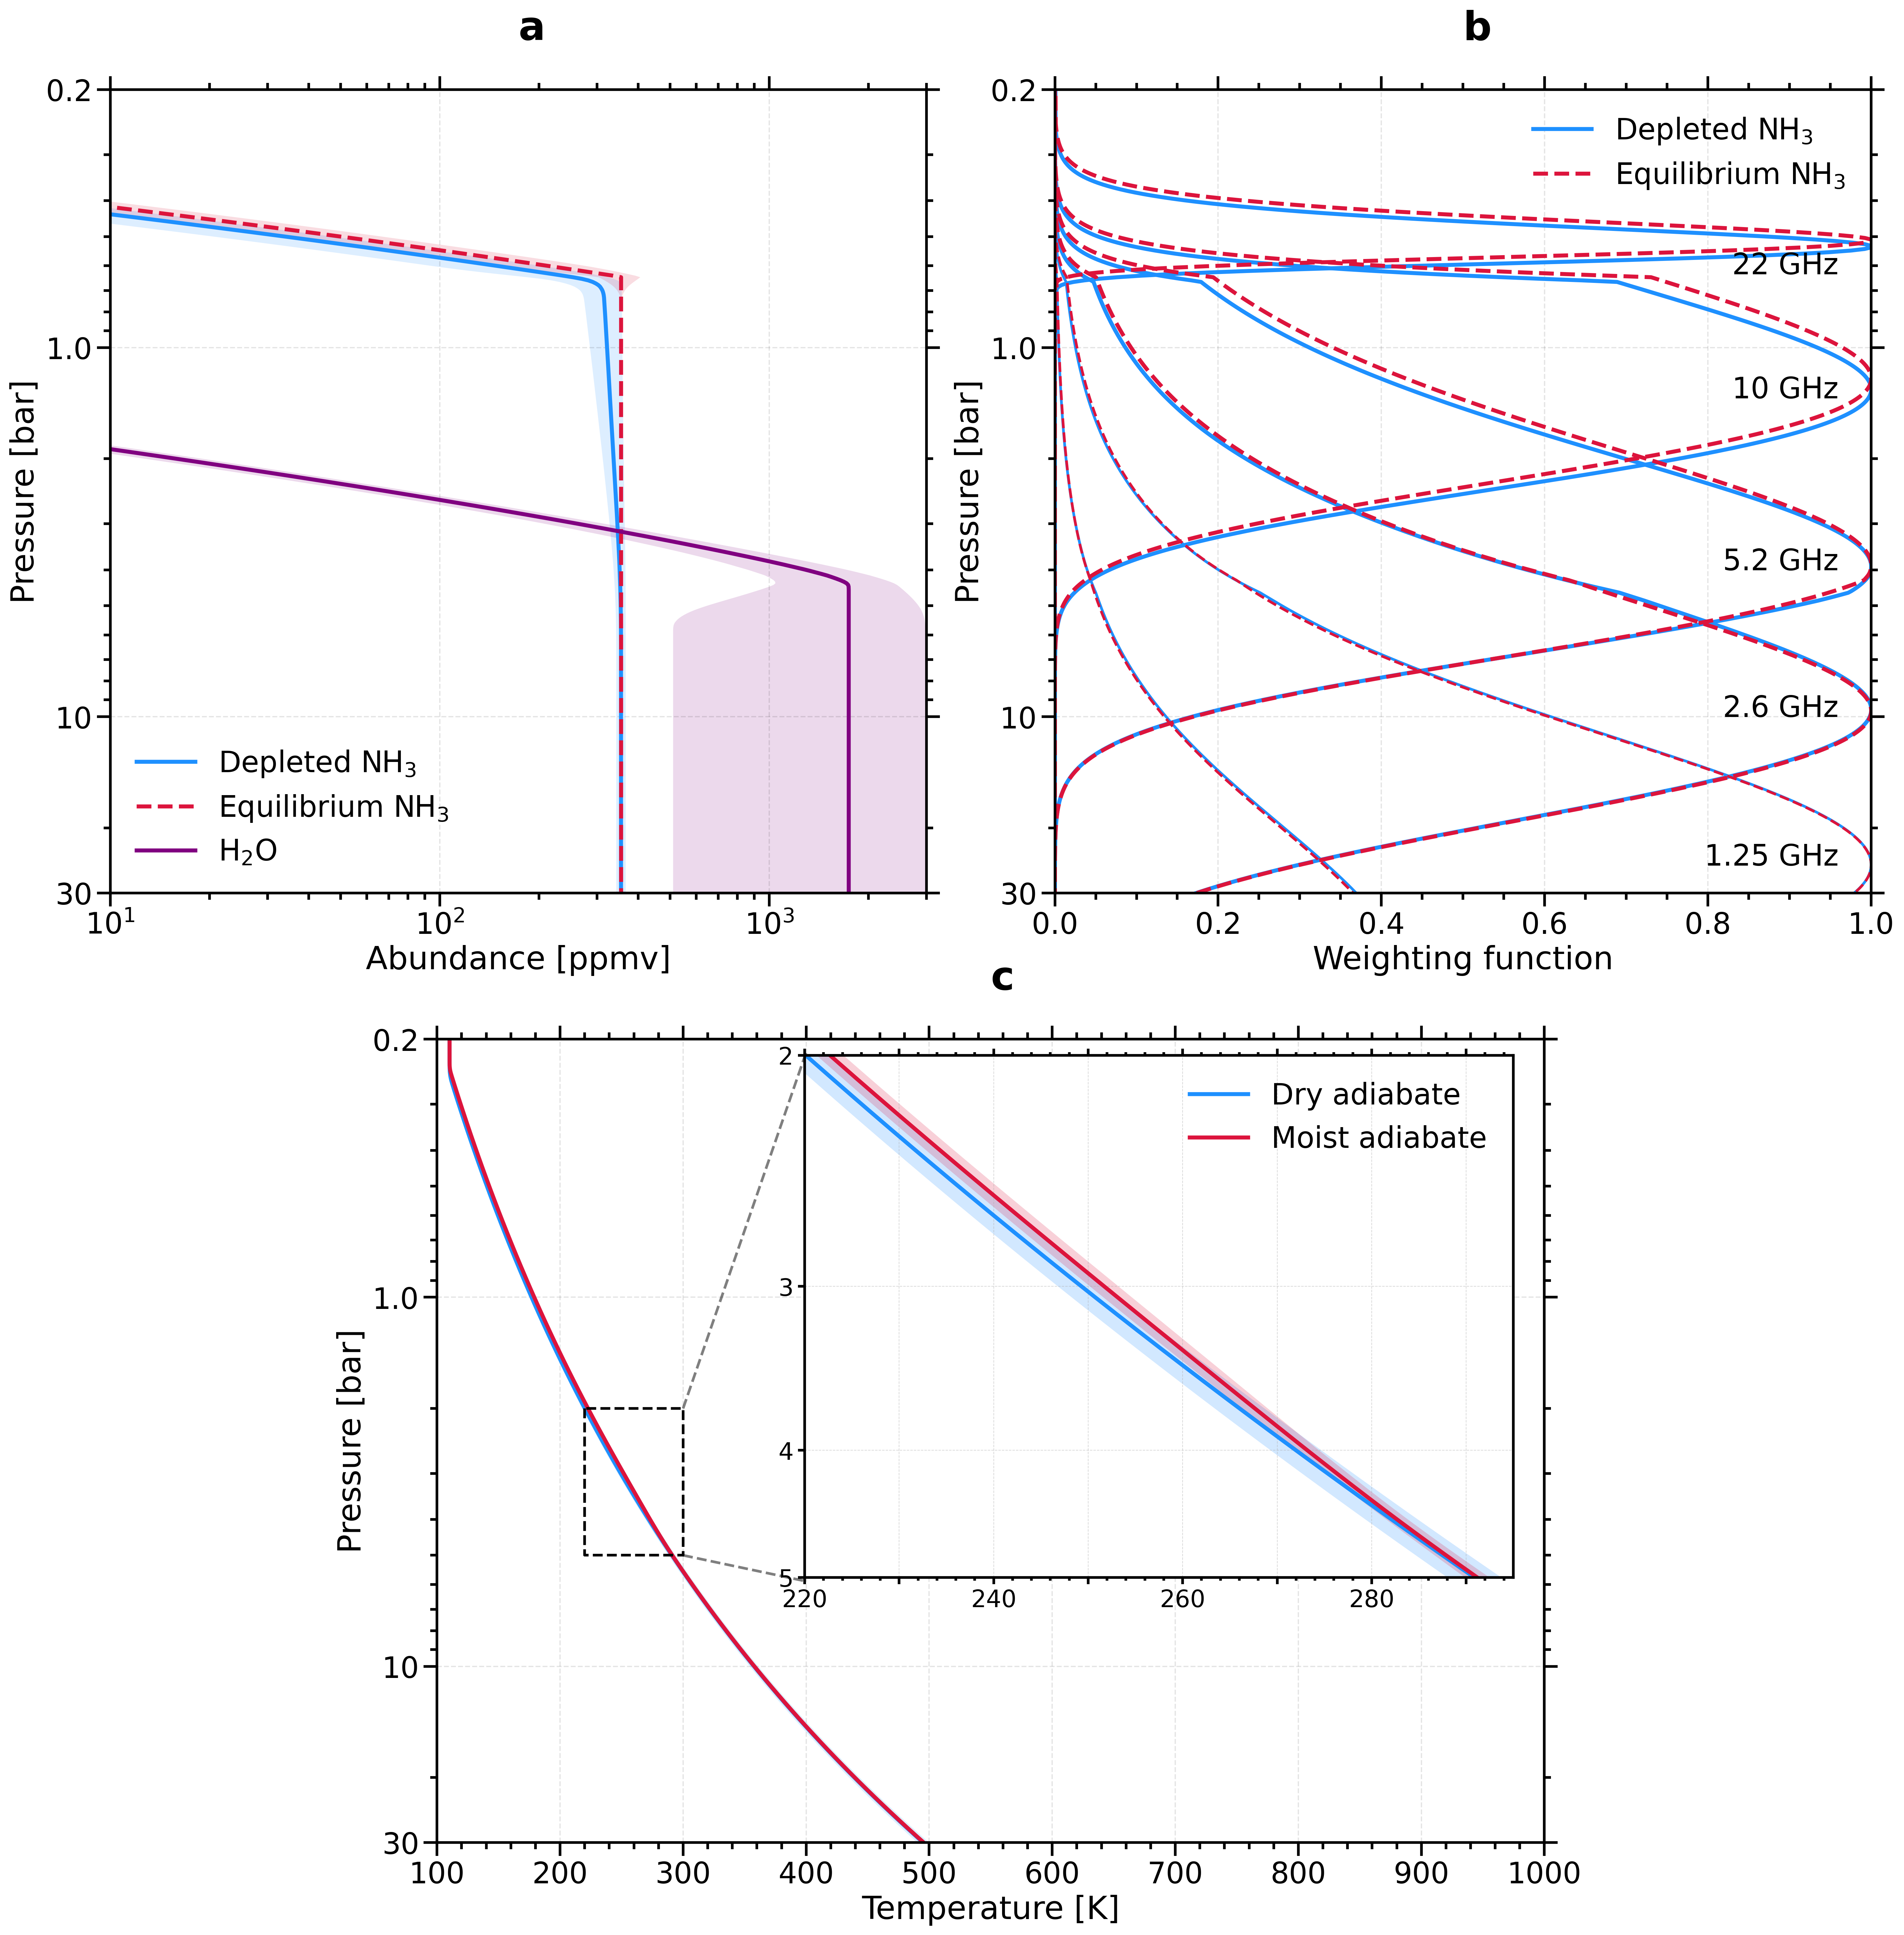

In [2]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator


# Open Juno MWR NetCDF file
juno = h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r")
pressure_bars = juno["press"][0,:,0,0] *1E-5

filename = "../../21.polarmean_redo/dry_adiab/reconstruct_atmos_profiles_last5000.h5"

with h5py.File(filename, 'r') as profIN:
    # Extract datasets
    SH_NH3_dry = profIN['NH3_ppmv'][:, :, :]
    SH_H2O_dry = profIN['H2O_ppmv'][:, :, :]
NH3_dry = np.median(SH_NH3_dry, axis=(0,1))
devNH3_dry = np.std(SH_NH3_dry, axis=(0,1))
H2O_dry = np.median(SH_H2O_dry, axis=(0,1))
devNH3_H2O = np.std(SH_H2O_dry, axis=(0,1))

filename = "../../21.polarmean_redo/moist_adiab/reconstruct_atmos_profiles_moist_last5000.h5"
with h5py.File(filename, 'r') as profIN:
    # Extract datasets
    SH_NH3_moist = profIN['NH3_ppmv'][:, :, :]
    SH_H2O = profIN['H2O_ppmv'][:, :, :]
NH3_moist = np.median(SH_NH3_moist, axis=(0,1))
devNH3_moist = np.std(SH_NH3_moist, axis=(0,1))

H2O_moist = np.median(SH_H2O, axis=(0,1))
devH2O_moist = np.std(SH_H2O, axis=(0,1))

fig = plt.figure(figsize=(20, 20), dpi=300)


ax1=fig.add_subplot(2, 2, 1)

# ax1=axs[0]
ax1.tick_params(axis='both', which='major', labelsize=22)
ax1.plot(NH3_dry, pressure_bars, 'dodgerblue', linewidth=3)
ax1.fill_betweenx(pressure_bars, NH3_dry - devNH3_dry, NH3_dry + devNH3_dry, color='dodgerblue', alpha=0.15, linewidth=0)

ax1.set_xlabel('Abundance [ppmv]', fontsize=24)

ax1.plot(NH3_moist, pressure_bars, 'crimson', linestyle='--', linewidth=3)
ax1.fill_betweenx(pressure_bars, NH3_moist - devNH3_moist, NH3_moist + devNH3_moist, color='crimson', alpha=0.15, linewidth=0)



# ax1.plot(H2O_dry, pressure_bars, 'dodgerblue', linestyle='-', linewidth=3)
# ax1.fill_betweenx(pressure_bars, H2O_dry - devNH3_H2O, H2O_dry + devNH3_H2O, color='dodgerblue', alpha=0.15, linewidth=0)

ax1.plot(H2O_moist, pressure_bars, 'purple', linestyle='-', linewidth=3)
ax1.fill_betweenx(pressure_bars, H2O_moist - devH2O_moist, H2O_moist + devH2O_moist, color='purple', alpha=0.15, linewidth=0)

# ax1.fill_betweenx([],[],[], color='dodgerblue', alpha=1, linewidth=0, label=r'H$_2$O')
# ax1.fill_betweenx([],[],[], color='crimson', alpha=1, linewidth=0, label=r'NH$_3$')

ax1.plot([],[], "-", color='dodgerblue', linewidth=3 ,  alpha=1,label=r'Depleted NH$_3$') 
ax1.plot([],[], "--", color='crimson',  linewidth=3 , alpha=1, label=r'Equilibrium NH$_3$')
ax1.plot([],[],  color='purple', linewidth=3 ,  alpha=1,label=r'H$_2$O')
# ax1.set_xlim(0,420)  # Inverted to match log scale
# ax1.set_xticks([0,100,200,300,400])
# ax1.set_xticklabels([0,100,200,300,400])
# ax1.xaxis.set_minor_locator(FixedLocator(range(0, 420, 20)))
ax1.set_xscale('log')
ax1.set_xlim(10, 3000)  # Inverted to match log scale
ax1.legend(frameon=False, fontsize=22, loc='lower left')


####


with h5py.File("/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/dry_adiab/reconstruct_temp_prof_dry_last5000.h5", "r") as profile:
    temp0 = profile["Temperature"][1000:, 0, :]
temp = np.mean(temp0, axis=0)
devtemp = np.std(temp0, axis=0)

with h5py.File("/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/moist_adiab/reconstruct_temp_prof_moist_last5000.h5", "r") as profile2:
    temp1 = profile2["Temperature"][3000:, 0, :]
temp_moist = np.mean(temp1, axis=0)
devtemp_moist = np.std(temp1, axis=0)


ax2=fig.add_subplot(2, 1, 2)
ax2.set_aspect(300)
ax2.plot(temp, pressure_bars, 'dodgerblue' , linewidth=3 ,  label='Dry adiabate')
ax2.fill_betweenx(pressure_bars, temp - devtemp, temp + devtemp, color='dodgerblue', alpha=0.15, linewidth=0)

ax2.plot(temp_moist, pressure_bars, 'crimson' , linewidth=3 ,  label='Moist adiabate')
ax2.fill_betweenx(pressure_bars, temp_moist - devtemp_moist, temp_moist + devtemp_moist, color='crimson', alpha=0.15, linewidth=0)

# ax2.legend(frameon=False)
ax2.set_xlabel(r'Temperature [K]',fontsize=24)

ax2.set_xlim(100,1000)  # Inverted to match log scale
ax2.set_xticks([100,200,300,400,500,600,700,800,900,1000])
ax2.set_xticklabels([100,200,300,400,500,600,700,800,900,1000]);


#plot polygon
ys=[2, 5, 5, 2, 2]
xs=[220, 220, 300, 300, 220]
ax2.plot(xs, ys, 'k--', lw=2, zorder=3)
ax2.plot([300, 400], [5, 5.88], 'k--', lw=2, alpha=0.5, zorder=3)
ax2.plot([300, 400], [2, 0.217], 'k--', lw=2, alpha=0.5, zorder=3)

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
zo = ax2.inset_axes([0.332, 0.33, 0.64, 0.65])
zo.plot(temp, pressure_bars, 'dodgerblue' , linewidth=3, label='Dry adiabate')
zo.fill_betweenx(pressure_bars, temp - devtemp, temp + devtemp, color='dodgerblue', alpha=0.2, linewidth=0)
zo.plot(temp_moist, pressure_bars, 'crimson' , linewidth=3, label='Moist adiabate')
zo.fill_betweenx(pressure_bars, temp_moist - devtemp_moist, temp_moist + devtemp_moist, color='crimson', alpha=0.2, linewidth=0)



zo.set_xlim(220,295)  # Inverted to match log scale
zo.set_yscale('log')
zo.set_ylim(5,2)  # Inverted to match log scale
zo.set_xticks([220,240,260,280,295])
zo.set_xticklabels([220,240,260,280,295], fontsize=18)
zo.set_yticks([5,4,3,2])
zo.set_yticklabels([5,4,3,2], fontsize=18)
zo.xaxis.set_minor_locator(FixedLocator(np.arange(220, 295, 2)))
zo.xaxis.set_major_locator(FixedLocator(np.arange(220, 295, 10)))
zo.tick_params(axis='both', which='major', length=5, width=2, labelsize=18, top=True, bottom=True)
zo.tick_params(axis='both', which='minor', length=2.5, width=2, top=True, bottom=True)

zo.grid(which='major', linestyle='--', linewidth=0.5, alpha=0.5)

# set spines width
zo.spines['right'].set_linewidth(2)
zo.spines['left'].set_linewidth(2)
zo.spines['bottom'].set_linewidth(2)
zo.spines['top'].set_linewidth(2)

zo.legend(frameon=False, fontsize=22, loc='upper right')


axtau=fig.add_subplot(2, 2, 2)
# clrs=['dodgerblue', 'crimson', 'darkorange', 'darkgreen', 'purple', 'black']

fname="/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/dry_adiab/juno_mwr_dryadiab_depletedNH3-main.nc"
w1, w2, w3, w4, w5, w6 = get_wt(fname)
# w1shallow=w1

# w1shallow[pressure_bars>100]=0

# print peak depth of weighting function
d1=pressure_bars[np.argmax(w1)]
d2=pressure_bars[np.argmax(w2)]
d3=pressure_bars[np.argmax(w3)]
d4=pressure_bars[np.argmax(w4)]
d5=pressure_bars[np.argmax(w5)]
d6=pressure_bars[np.argmax(w6)]
print(f"Peak depth of weighting function: {d1:.2f} bar, {d2:.2f} bar, {d3:.2f} bar, {d4:.2f} bar, {d5:.2f} bar, {d6:.2f} bar")

# the depths of half maximum of weighting function
h1=pressure_bars[np.where(w1>=0.5)[0][-1]]-d1
h2=pressure_bars[np.where(w2>=0.5)[0][-1]]-d2
h3=pressure_bars[np.where(w3>=0.5)[0][-1]]-d3
h4=pressure_bars[np.where(w4>=0.5)[0][-1]]-d4
h5=pressure_bars[np.where(w5>=0.5)[0][-1]]-d5
h6=pressure_bars[np.where(w6>=0.5)[0][-1]]-d6
print(f"Depths of half maximum of weighting function: {h1:.2f} bar, {h2:.2f} bar, {h3:.2f} bar, {h4:.2f} bar, {h5:.2f} bar, {h6:.2f} bar")

# the depths of half maximum of weighting function
h1=pressure_bars[np.where(w1>=0.5)[0][0]]-d1
h2=pressure_bars[np.where(w2>=0.5)[0][0]]-d2
h3=pressure_bars[np.where(w3>=0.5)[0][0]]-d3
h4=pressure_bars[np.where(w4>=0.5)[0][0]]-d4
h5=pressure_bars[np.where(w5>=0.5)[0][0]]-d5
h6=pressure_bars[np.where(w6>=0.5)[0][0]]-d6
print(f"Depths of half maximum of weighting function: {h1:.2f} bar, {h2:.2f} bar, {h3:.2f} bar, {h4:.2f} bar, {h5:.2f} bar, {h6:.2f} bar")


axtau.plot(w1, pressure_bars, linestyle="-", color="dodgerblue", linewidth=2)
axtau.plot(w2, pressure_bars, linestyle="-", color="dodgerblue", linewidth=2)
axtau.plot(w3, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3, label=r"Depleted NH$_3$")
axtau.plot(w4, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3)
axtau.plot(w5, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3)
axtau.plot(w6, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3)


fname="/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/moist_adiab/juno_mwr_moistdiab_rhmax-main.nc"
w1, w2, w3, w4, w5, w6 = get_wt(fname)
axtau.plot(w1, pressure_bars, linestyle="--", color="crimson", linewidth=2)
axtau.plot(w2, pressure_bars, linestyle="--", color="crimson", linewidth=2)
axtau.plot(w3, pressure_bars, linestyle="--", color="crimson", linewidth=3, label=r"Equilibrium NH$_3$")
axtau.plot(w4, pressure_bars, linestyle="--", color="crimson", linewidth=3)
axtau.plot(w5, pressure_bars, linestyle="--", color="crimson", linewidth=3)
axtau.plot(w6, pressure_bars, linestyle="--", color="crimson", linewidth=3)


axtau.legend(frameon=False, fontsize=22, loc='upper right')

axtau.text(0.96, 0.6, "22 GHz", fontsize=22, va='center', ha='right')
axtau.text(0.96, 1.3, "10 GHz", fontsize=22, va='center', ha='right')
axtau.text(0.96, 3.8,  "5.2 GHz", fontsize=22, va='center', ha='right')
axtau.text(0.96, 9.5, "2.6 GHz", fontsize=22, va='center', ha='right')
axtau.text(0.96, 24, "1.25 GHz", fontsize=22, va='center', ha='right')
axtau.set_xlabel(r'Weighting function', fontsize=24)

axtau.set_xlim(0,1)

axs= [ax1, axtau, ax2]
for i, ax in enumerate(axs):

    ax.set_ylabel('Pressure [bar]',fontsize=24)
    ax.set_yscale('log')

    ax.grid(linestyle='--', linewidth=1, color='k', alpha=0.1)

    from matplotlib.ticker import FixedLocator

    ax.minorticks_on()
    ax.yaxis.set_minor_locator(FixedLocator([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1,2,3,4,5,6,7,8,9,10,20,30]))
    ax.set_yticks([0.2, 1, 10, 30])
    ax.set_yticklabels([0.2, 1.0, 10, 30])
    ax.yaxis.set_ticks_position('both')

    ## set a y tick length
    ax.tick_params(axis='both', which='major', length=10, width=2,top =True, labelsize=22)
    ax.tick_params(axis='both', which='minor', length=5, width=2,top =True)

    # # set spine line width
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)



    ax.set_ylim( 30,0.2)  # Inverted to match log scale

    ax.text(0.5, 1.1, f"{chr(97+i)}", fontsize=30, fontweight='bold', va='top', ha='left', transform=ax.transAxes)

fig.subplots_adjust(hspace=1, wspace=0.3)

plt.tight_layout()


plt.show()

In [3]:
peaks=[60.59 , 25.10 , 9.62 , 3.91 , 1.29 , 0.53 ]

import h5py

with h5py.File("/data/jihenghu/juno-mwr-deconv-research/24.cpc_retrieve_redo/cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r") as f:
    x1=f["x1"][:]

print(x1)
print(pressure_bars)

for ip, peak in enumerate(peaks):
    idx = (np.abs(pressure_bars - peak)).argmin()
    print(f"Channel {ip+1}: Closest index to peak {peak} is {idx}, x1 value is {x1[idx]}")


[-269853.12 -269559.38 -269265.62 ...  199265.62  199559.38  199853.12]
[8.1030840e+03 8.0241284e+03 7.9459424e+03 ... 1.2978017e-03 1.2851562e-03
 1.2726338e-03]
Channel 1: Closest index to peak 60.59 is 500, x1 value is -122978.125
Channel 2: Closest index to peak 25.1 is 590, x1 value is -96540.625
Channel 3: Closest index to peak 9.62 is 688, x1 value is -67753.125
Channel 4: Closest index to peak 3.91 is 780, x1 value is -40728.125
Channel 5: Closest index to peak 1.29 is 893, x1 value is -7534.375
Channel 6: Closest index to peak 0.53 is 984, x1 value is 19196.875


Peak depth of weighting function: 1273.31 bar, 25.10 bar, 9.62 bar, 3.91 bar, 1.29 bar, 0.53 bar
Depths of half maximum of weighting function: -342.51 bar, -16.80 bar, -6.04 bar, -2.44 bar, -0.65 bar, -0.07 bar
Depths of half maximum of weighting function: 260.36 bar, 46.47 bar, 10.62 bar, 3.26 bar, 1.20 bar, 0.06 bar


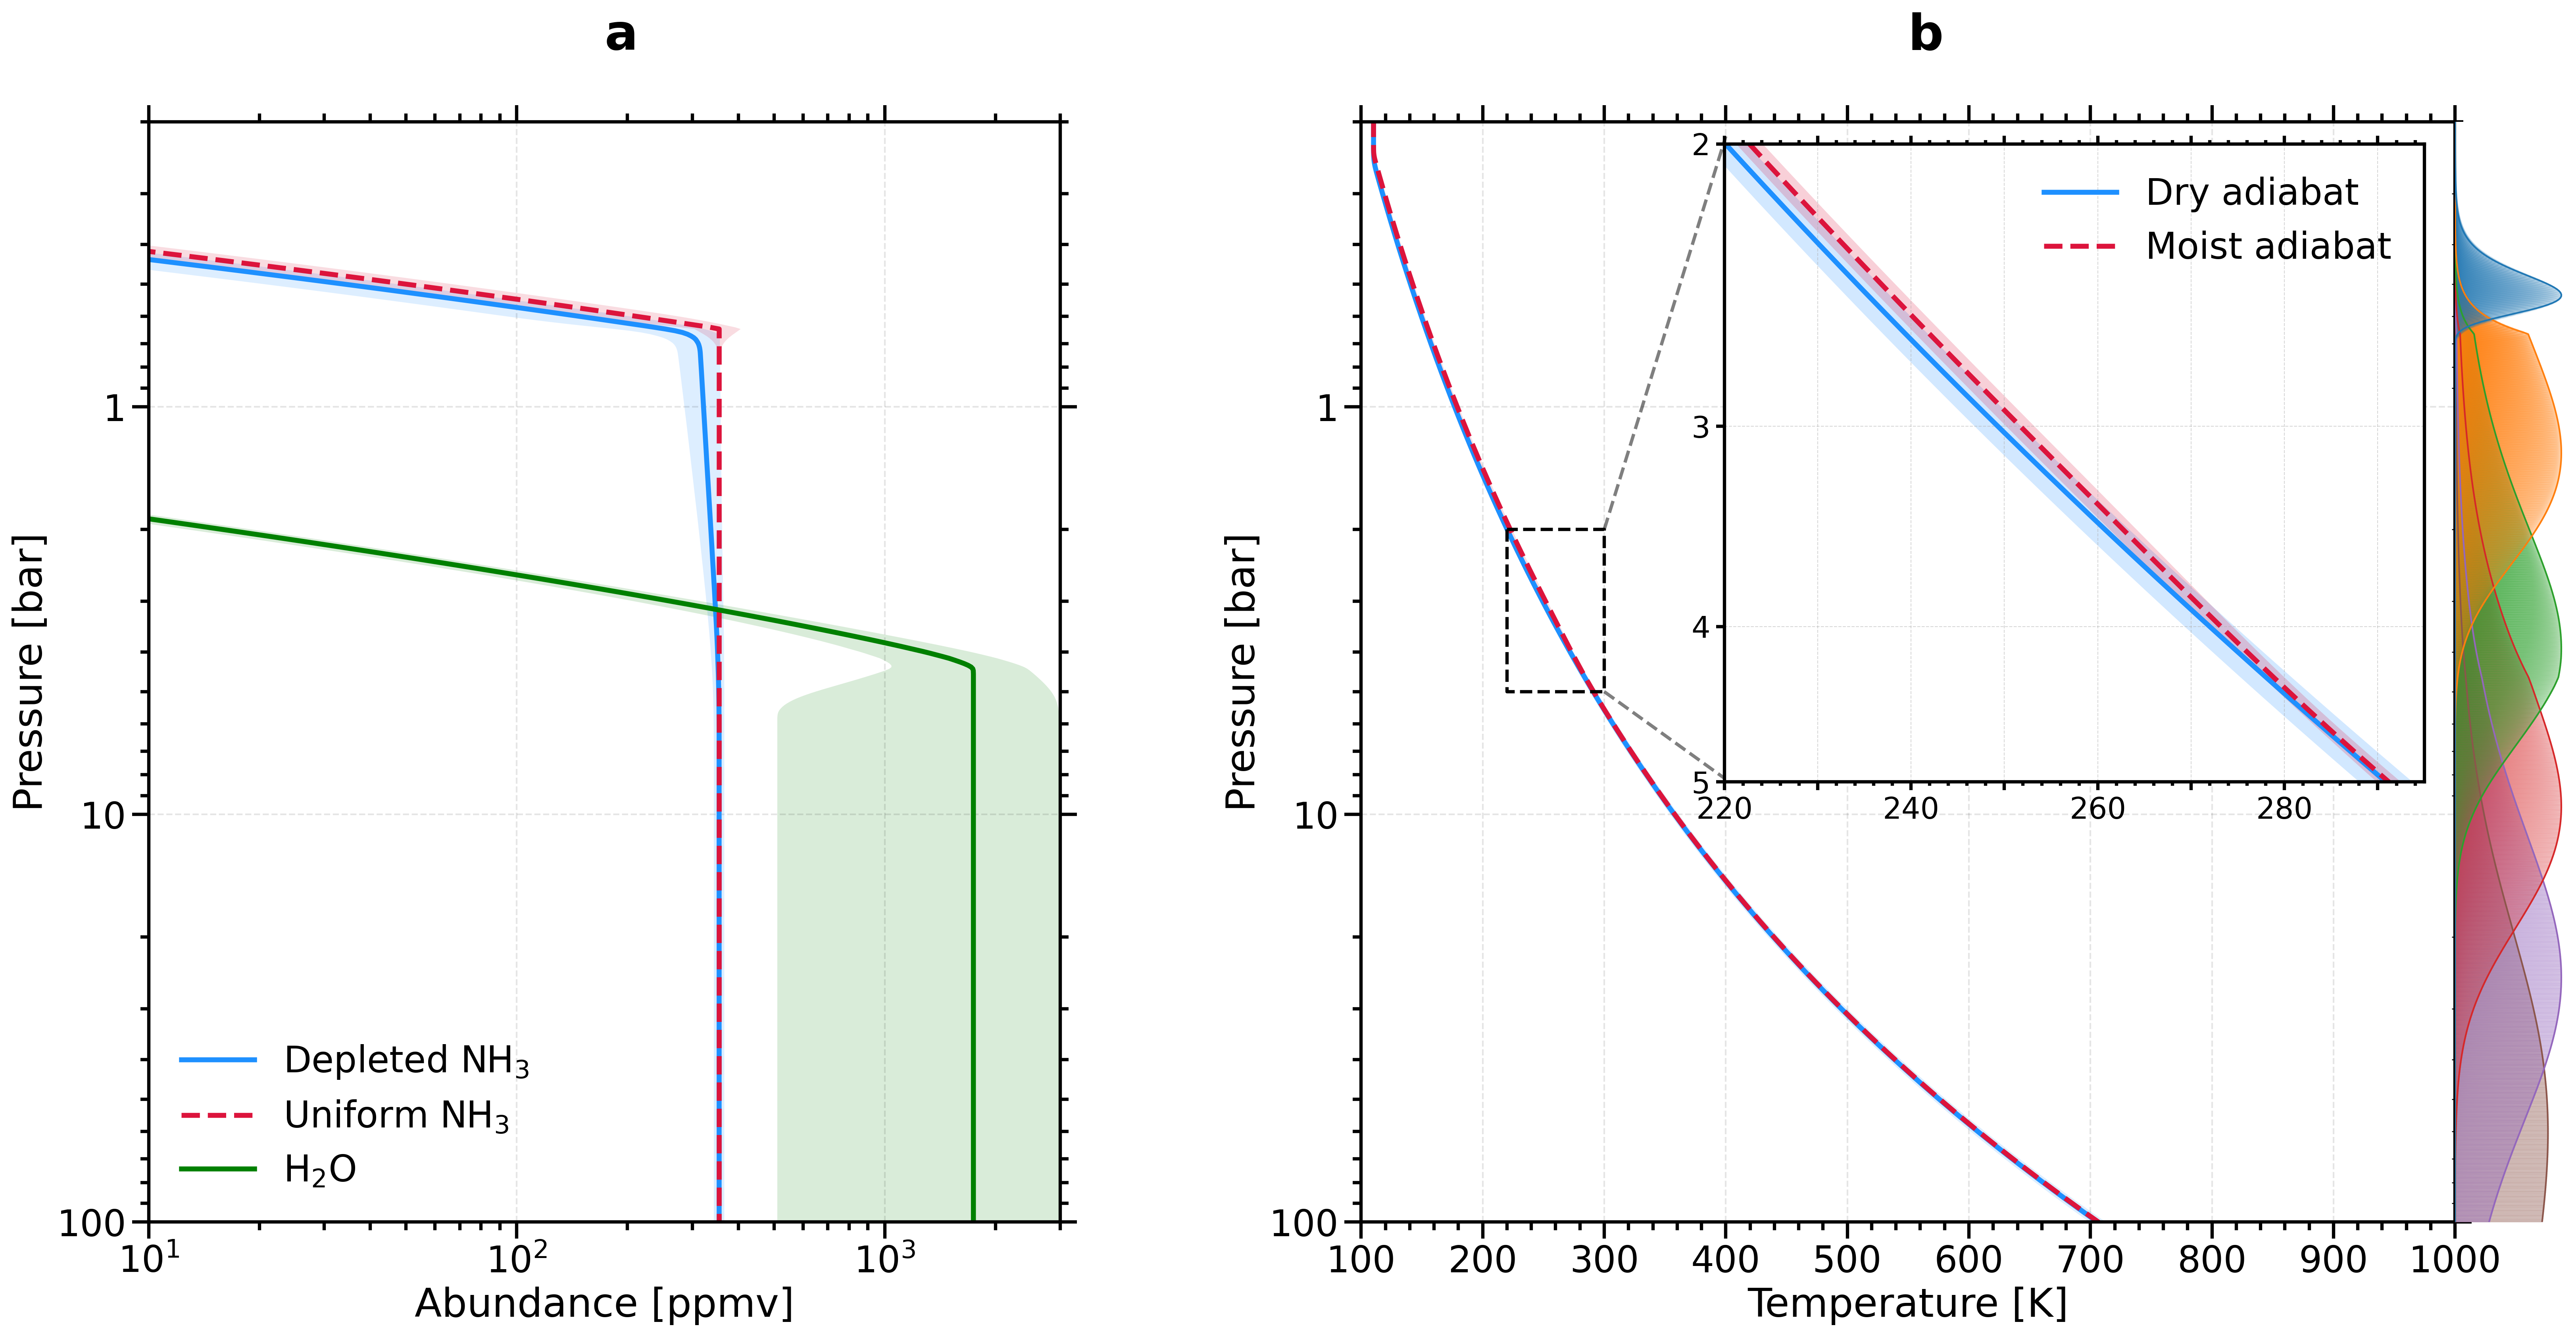

In [67]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator


# Open Juno MWR NetCDF file
juno = h5py.File("../cpc_dry/bin/juno_forward_mwr_polarmean-main.nc", "r")
pressure_bars = juno["press"][0,:,0,0] *1E-5

filename = "../../21.polarmean_redo/dry_adiab/reconstruct_atmos_profiles_last5000.h5"

with h5py.File(filename, 'r') as profIN:
    # Extract datasets
    SH_NH3_dry = profIN['NH3_ppmv'][:, :, :]
    SH_H2O_dry = profIN['H2O_ppmv'][:, :, :]
NH3_dry = np.median(SH_NH3_dry, axis=(0,1))
devNH3_dry = np.std(SH_NH3_dry, axis=(0,1))
H2O_dry = np.median(SH_H2O_dry, axis=(0,1))
devNH3_H2O = np.std(SH_H2O_dry, axis=(0,1))

filename = "../../21.polarmean_redo/moist_adiab/reconstruct_atmos_profiles_moist_last5000.h5"
with h5py.File(filename, 'r') as profIN:
    # Extract datasets
    SH_NH3_moist = profIN['NH3_ppmv'][:, :, :]
    SH_H2O = profIN['H2O_ppmv'][:, :, :]
NH3_moist = np.median(SH_NH3_moist, axis=(0,1))
devNH3_moist = np.std(SH_NH3_moist, axis=(0,1))

H2O_moist = np.median(SH_H2O, axis=(0,1))
devH2O_moist = np.std(SH_H2O, axis=(0,1))

fig , [ax1, ax2]=plt.subplots(1,2, figsize=(25, 12), dpi=300, width_ratios=[1, 1.2])
fig.subplots_adjust(wspace=8)


# ax1=axs[0]
ax1.tick_params(axis='both', which='major', labelsize=22)
ax1.plot(NH3_dry, pressure_bars, 'dodgerblue', linewidth=3)
ax1.fill_betweenx(pressure_bars, NH3_dry - devNH3_dry, NH3_dry + devNH3_dry, color='dodgerblue', alpha=0.15, linewidth=0)

ax1.set_xlabel('Abundance [ppmv]', fontsize=24)

ax1.plot(NH3_moist, pressure_bars, 'crimson', linestyle='--', linewidth=3)
ax1.fill_betweenx(pressure_bars, NH3_moist - devNH3_moist, NH3_moist + devNH3_moist, color='crimson', alpha=0.15, linewidth=0)



# ax1.plot(H2O_dry, pressure_bars, 'dodgerblue', linestyle='-', linewidth=3)
# ax1.fill_betweenx(pressure_bars, H2O_dry - devNH3_H2O, H2O_dry + devNH3_H2O, color='dodgerblue', alpha=0.15, linewidth=0)

ax1.plot(H2O_moist, pressure_bars, 'green', linestyle='-', linewidth=3)
ax1.fill_betweenx(pressure_bars, H2O_moist - devH2O_moist, H2O_moist + devH2O_moist, color='green', alpha=0.15, linewidth=0)

# ax1.fill_betweenx([],[],[], color='dodgerblue', alpha=1, linewidth=0, label=r'H$_2$O')
# ax1.fill_betweenx([],[],[], color='crimson', alpha=1, linewidth=0, label=r'NH$_3$')

ax1.plot([],[], "-", color='dodgerblue', linewidth=3 ,  alpha=1,label=r'Depleted NH$_3$') 
ax1.plot([],[], "--", color='crimson',  linewidth=3 , alpha=1, label=r'Uniform NH$_3$')
ax1.plot([],[],  color='green', linewidth=3 ,  alpha=1,label=r'H$_2$O')
# ax1.set_xlim(0,420)  # Inverted to match log scale
# ax1.set_xticks([0,100,200,300,400])
# ax1.set_xticklabels([0,100,200,300,400])
# ax1.xaxis.set_minor_locator(FixedLocator(range(0, 420, 20)))
ax1.set_xscale('log')
ax1.set_xlim(10, 3000)  # Inverted to match log scale
ax1.legend(frameon=False, fontsize=22, loc='lower left')


####


with h5py.File("/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/dry_adiab/reconstruct_temp_prof_dry_last5000.h5", "r") as profile:
    temp0 = profile["Temperature"][1000:, 0, :]
temp = np.mean(temp0, axis=0)
devtemp = np.std(temp0, axis=0)

with h5py.File("/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/moist_adiab/reconstruct_temp_prof_moist_last5000.h5", "r") as profile2:
    temp1 = profile2["Temperature"][3000:, 0, :]
temp_moist = np.mean(temp1, axis=0)
devtemp_moist = np.std(temp1, axis=0)



# ax2.set_aspect(300)
ax2.plot(temp, pressure_bars, 'dodgerblue' , linewidth=3 ,  label='Dry adiabate')
ax2.fill_betweenx(pressure_bars, temp - devtemp, temp + devtemp, color='dodgerblue', alpha=0.15, linewidth=0)

ax2.plot(temp_moist, pressure_bars, '--', color='crimson' , linewidth=3 ,  label='Moist adiabate')
ax2.fill_betweenx(pressure_bars, temp_moist - devtemp_moist, temp_moist + devtemp_moist, color='crimson', alpha=0.15, linewidth=0)

# ax2.legend(frameon=False)
ax2.set_xlabel(r'Temperature [K]',fontsize=24)

ax2.set_xlim(100,1000)  # Inverted to match log scale
ax2.set_xticks([100,200,300,400,500,600,700,800,900,1000])
ax2.set_xticklabels([100,200,300,400,500,600,700,800,900,1000]);


#plot polygon
ys=[2, 5, 5, 2, 2]
xs=[220, 220, 300, 300, 220]
ax2.plot(xs, ys, 'k--', lw=2, zorder=3)
ax2.plot([300, 400], [5, 8.2], 'k--', lw=2, alpha=0.5, zorder=3)
ax2.plot([300, 400], [2, 0.217], 'k--', lw=2, alpha=0.5, zorder=3)

from mpl_toolkits.axes_grid1.inset_locator import inset_axes
zo = ax2.inset_axes([0.332, 0.40, 0.64, 0.58])
zo.plot(temp, pressure_bars, '-', color='dodgerblue' , linewidth=3, label='Dry adiabat')
zo.fill_betweenx(pressure_bars, temp - devtemp, temp + devtemp, color='dodgerblue', alpha=0.2, linewidth=0)
zo.plot(temp_moist, pressure_bars, '--', color='crimson' , linewidth=3, label='Moist adiabat')
zo.fill_betweenx(pressure_bars, temp_moist - devtemp_moist, temp_moist + devtemp_moist, color='crimson', alpha=0.2, linewidth=0)



zo.set_xlim(220,295)  # Inverted to match log scale
zo.set_yscale('log')
zo.set_ylim(5,2)  # Inverted to match log scale
zo.set_xticks([220,240,260,280,295])
zo.set_xticklabels([220,240,260,280,295], fontsize=18)
zo.set_yticks([5,4,3,2])
zo.set_yticklabels([5,4,3,2], fontsize=18)
zo.xaxis.set_minor_locator(FixedLocator(np.arange(220, 295, 2)))
zo.xaxis.set_major_locator(FixedLocator(np.arange(220, 295, 10)))
zo.tick_params(axis='both', which='major', length=5, width=2, labelsize=18, top=True, bottom=True)
zo.tick_params(axis='both', which='minor', length=2.5, width=2, top=True, bottom=True)

zo.grid(which='major', linestyle='--', linewidth=0.5, alpha=0.5)

# set spines width
zo.spines['right'].set_linewidth(2)
zo.spines['left'].set_linewidth(2)
zo.spines['bottom'].set_linewidth(2)
zo.spines['top'].set_linewidth(2)

zo.legend(frameon=False, fontsize=22, loc='upper right')


axtau=ax2.inset_axes([1, 0., 0.1, 1])
# clrs=['dodgerblue', 'crimson', 'darkorange', 'darkgreen', 'purple', 'black']

fname="/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/dry_adiab/juno_mwr_dryadiab_depletedNH3-main.nc"
w1, w2, w3, w4, w5, w6 = get_wt(fname)

# print peak depth of weighting function
d1=pressure_bars[np.argmax(w1)]
d2=pressure_bars[np.argmax(w2)]
d3=pressure_bars[np.argmax(w3)]
d4=pressure_bars[np.argmax(w4)]
d5=pressure_bars[np.argmax(w5)]
d6=pressure_bars[np.argmax(w6)]
print(f"Peak depth of weighting function: {d1:.2f} bar, {d2:.2f} bar, {d3:.2f} bar, {d4:.2f} bar, {d5:.2f} bar, {d6:.2f} bar")

# the depths of half maximum of weighting function
h1=pressure_bars[np.where(w1>=0.5)[0][-1]]-d1
h2=pressure_bars[np.where(w2>=0.5)[0][-1]]-d2
h3=pressure_bars[np.where(w3>=0.5)[0][-1]]-d3
h4=pressure_bars[np.where(w4>=0.5)[0][-1]]-d4
h5=pressure_bars[np.where(w5>=0.5)[0][-1]]-d5
h6=pressure_bars[np.where(w6>=0.5)[0][-1]]-d6
print(f"Depths of half maximum of weighting function: {h1:.2f} bar, {h2:.2f} bar, {h3:.2f} bar, {h4:.2f} bar, {h5:.2f} bar, {h6:.2f} bar")

# the depths of half maximum of weighting function
h1=pressure_bars[np.where(w1>=0.5)[0][0]]-d1
h2=pressure_bars[np.where(w2>=0.5)[0][0]]-d2
h3=pressure_bars[np.where(w3>=0.5)[0][0]]-d3
h4=pressure_bars[np.where(w4>=0.5)[0][0]]-d4
h5=pressure_bars[np.where(w5>=0.5)[0][0]]-d5
h6=pressure_bars[np.where(w6>=0.5)[0][0]]-d6
print(f"Depths of half maximum of weighting function: {h1:.2f} bar, {h2:.2f} bar, {h3:.2f} bar, {h4:.2f} bar, {h5:.2f} bar, {h6:.2f} bar")


# axtau.plot(w1, pressure_bars, linestyle="-", color="dodgerblue", linewidth=2)
# axtau.plot(w2, pressure_bars, linestyle="-", color="dodgerblue", linewidth=2)
# axtau.plot(w3, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3, label=r"Depleted NH$_3$")
# axtau.plot(w4, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3)
# axtau.plot(w5, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3)
# axtau.plot(w6, pressure_bars, linestyle="-", color="dodgerblue", linewidth=3)

import numpy as np

# get six colors from inforno sequence
colors = plt.cm.tab10.colors[:6][::-1]
opacities = [0.4,0.4,0.3,0.3,0.2,0.1]
for i1, ws in enumerate([w1*2, w2, w3, w4, w5, w6]):
    axtau.plot(ws, pressure_bars, linestyle="-", color=colors[i1], linewidth=1, alpha=1)
    for p, w in zip(pressure_bars, ws):
        y = np.linspace(p - 0.08, p + 0.08, 100)
        sigma = 0.02
        x = w * np.exp(-(y - p)**2 / (2 * sigma**2))

        axtau.fill_betweenx(
            y, 0, x,
            color=colors[i1],
            alpha=opacities[i1]
        )


# fname="/data/jihenghu/juno-mwr-deconv-research/21.polarmean_redo/moist_adiab/juno_mwr_moistdiab_rhmax-main.nc"
# w1, w2, w3, w4, w5, w6 = get_wt(fname)
# axtau.plot(w1, pressure_bars, linestyle="--", color="crimson", linewidth=2)
# axtau.plot(w2, pressure_bars, linestyle="--", color="crimson", linewidth=2)
# axtau.plot(w3, pressure_bars, linestyle="--", color="crimson", linewidth=3, label=r"Equilibrium NH$_3$")
# axtau.plot(w4, pressure_bars, linestyle="--", color="crimson", linewidth=3)
# axtau.plot(w5, pressure_bars, linestyle="--", color="crimson", linewidth=3)
# axtau.plot(w6, pressure_bars, linestyle="--", color="crimson", linewidth=3)


# axtau.legend(frameon=False, fontsize=22, loc='upper right')

# axtau.text(0.96, 0.6, "22 GHz", fontsize=22, va='center', ha='right')
# axtau.text(0.96, 1.3, "10 GHz", fontsize=22, va='center', ha='right')
# axtau.text(0.96, 3.8,  "5.2 GHz", fontsize=22, va='center', ha='right')
# axtau.text(0.96, 9.5, "2.6 GHz", fontsize=22, va='center', ha='right')
# axtau.text(0.96, 24, "1.25 GHz", fontsize=22, va='center', ha='right')
# axtau.set_xlabel(r'Weighting function', fontsize=24)

axtau.set_xlim(0,1.03)

for spine in axtau.spines.values():
    spine.set_visible(False)
axtau.set_yscale('log')
axtau.set_ylim(100,0.2)  
axtau.set_xticks([], labels=[])
axtau.set_yticks([], labels=[])

axs= [ax1, ax2]
for i, ax in enumerate(axs):

    ax.set_ylabel('Pressure [bar]',fontsize=24)
    ax.set_yscale('log')

    ax.grid(linestyle='--', linewidth=1, color='k', alpha=0.1)

    from matplotlib.ticker import FixedLocator

    ax.minorticks_on()
    # ax.yaxis.set_minor_locator(FixedLocator([0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1,2,3,4,5,6,7,8,9,10,20,30,40,50,60,70,80,90,100]))
    ax.set_yticks([1, 10, 100])
    ax.set_yticklabels([1, 10, 100])
    ax.yaxis.set_ticks_position('both')

    ## set a y tick length
    ax.tick_params(axis='both', which='major', length=10, width=2,top =True, labelsize=22)
    ax.tick_params(axis='both', which='minor', length=5, width=2,top =True)

    # # set spine line width
    for axis in ['top','bottom','left','right']:
        ax.spines[axis].set_linewidth(2)



    ax.set_ylim(100,0.2)  # Inverted to match log scale

    ax.text(0.5, 1.1, f"{chr(97+i)}", fontsize=30, fontweight='bold', va='top', ha='left', transform=ax.transAxes)

fig.subplots_adjust(wspace=0.3)

# plt.tight_layout()


plt.show()